In [ ]:
# ============================================
# TRAVEL TIME PREDICTION
# Ridge and Lasso Regression
# ============================================

from google.colab import files

uploaded = files.upload()

Saving travel_time_prediction_dataset_1000.csv to travel_time_prediction_dataset_1000.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import Ridge, Lasso

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Load CSV
df = pd.read_csv("Data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (1000, 6)


,distance_km,traffic_level,weather,day_of_week,departure_hour,travel_time_minutes
0,41.74,Medium,Rainy,Wednesday,14,86.81
1,73.63,Low,Sunny,Sunday,11,73.55
2,40.26,Low,Cloudy,Friday,15,52.66
3,79.38,Medium,Cloudy,Thursday,23,122.40
4,68.26,High,Sunny,Monday,18,141.84


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

Number of rows: 1000
Number of columns: 6

Column Names:
['distance_km', 'traffic_level', 'weather', 'day_of_week', 'departure_hour', 'travel_time_minutes']

Data Types:
distance_km            float64
traffic_level           object
weather                 object
day_of_week             object
departure_hour           int64
travel_time_minutes    float64
dtype: object

Missing Values:
distance_km            0
traffic_level          0
weather                0
day_of_week            0
departure_hour         0
travel_time_minutes    0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   distance_km          1000 non-null   float64
 1   traffic_level        1000 non-null   object 
 2   weather              1000 non-null   object 
 3   day_of_week          1000 non-null   object 
 4   departure_hour    

In [ ]:
print("Statistical Summary:")
display(df.describe(include="all"))

Statistical Summary:


,distance_km,traffic_level,weather,day_of_week,departure_hour,travel_time_minutes
count,1000.00000,1000,1000,1000,1000.000000,1000.00000
unique,NaN,4,4,7,NaN,NaN
top,NaN,Medium,Sunny,Monday,NaN,NaN
freq,NaN,370,454,178,NaN,NaN
mean,40.50675,NaN,NaN,NaN,11.303000,70.37553
std,22.81288,NaN,NaN,NaN,6.838125,45.45267
min,1.01000,NaN,NaN,NaN,0.000000,3.00000
25%,21.48750,NaN,NaN,NaN,5.000000,34.13250
50%,40.62500,NaN,NaN,NaN,11.000000,65.75000
75%,60.53000,NaN,NaN,NaN,17.000000,99.05000


In [ ]:
print("Traffic Levels:")
print(df["traffic_level"].unique())

print("\nWeather Conditions:")
print(df["weather"].unique())

print("\nDays of Week:")
print(df["day_of_week"].unique())

Traffic Levels:
['Medium' 'Low' 'High' 'Very High']

Weather Conditions:
['Rainy' 'Sunny' 'Cloudy' 'Foggy']

Days of Week:
['Wednesday' 'Sunday' 'Friday' 'Thursday' 'Monday' 'Saturday' 'Tuesday']


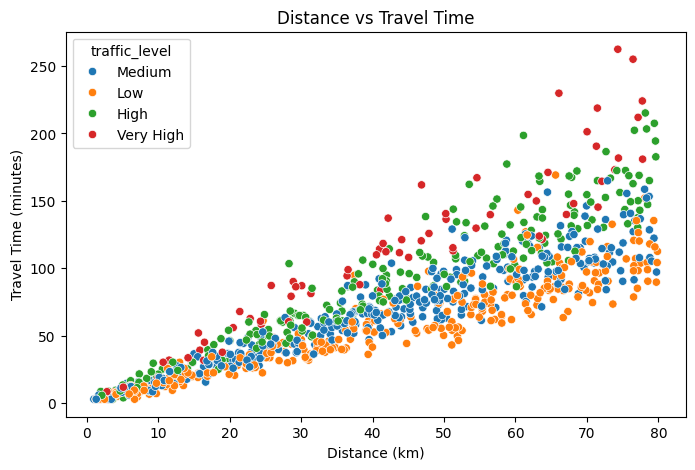

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="distance_km",
    y="travel_time_minutes",
    hue="traffic_level"
)

plt.title("Distance vs Travel Time")
plt.xlabel("Distance (km)")
plt.ylabel("Travel Time (minutes)")
plt.show()

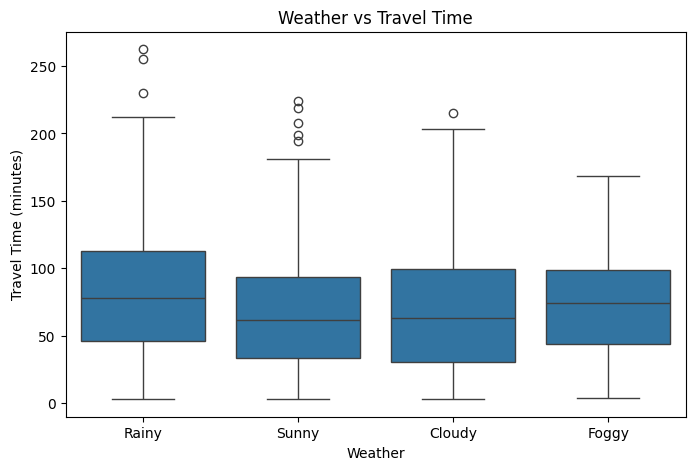

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="weather",
    y="travel_time_minutes"
)

plt.title("Weather vs Travel Time")
plt.xlabel("Weather")
plt.ylabel("Travel Time (minutes)")
plt.show()

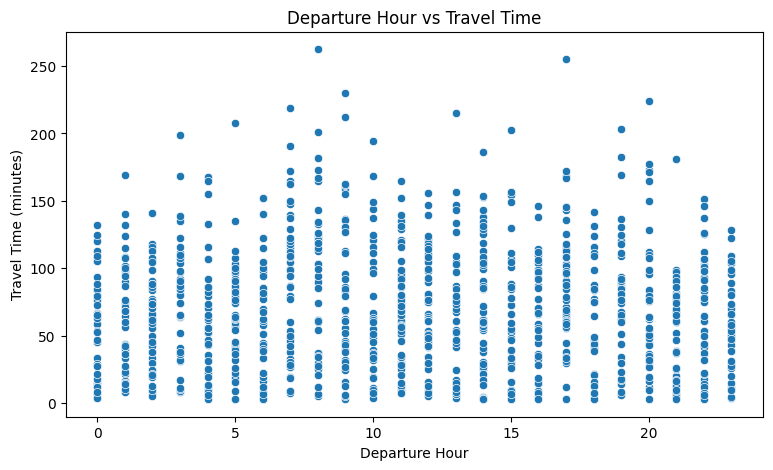

In [ ]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="departure_hour",
    y="travel_time_minutes"
)

plt.title("Departure Hour vs Travel Time")
plt.xlabel("Departure Hour")
plt.ylabel("Travel Time (minutes)")
plt.show()

In [ ]:
# Features
X = df[
    [
        "distance_km",
        "traffic_level",
        "weather",
        "day_of_week",
        "departure_hour"
    ]
]

# Target
y = df["travel_time_minutes"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 5)
y shape: (1000,)


In [ ]:
numerical_features = [
    "distance_km",
    "departure_hour"
]

categorical_features = [
    "traffic_level",
    "weather",
    "day_of_week"
]

In [ ]:
numerical_features = [
    "distance_km",
    "departure_hour"
]

categorical_features = [
    "traffic_level",
    "weather",
    "day_of_week"
]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

ridge_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "regressor",
            Ridge(alpha=1.0)
        )
    ]
)

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

print("Ridge Regression training completed!")

Ridge Regression training completed!


In [ ]:
lasso_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "regressor",
            Lasso(alpha=0.1, max_iter=10000)
        )
    ]
)

lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_test)

print("Lasso Regression training completed!")

Lasso Regression training completed!


In [ ]:
def evaluate_model(y_actual, y_predicted):

    mae = mean_absolute_error(
        y_actual,
        y_predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_actual,
            y_predicted
        )
    )

    r2 = r2_score(
        y_actual,
        y_predicted
    )

    return mae, rmse, r2

In [ ]:
ridge_mae, ridge_rmse, ridge_r2 = evaluate_model(
    y_test,
    ridge_predictions
)

print("================================")
print("RIDGE REGRESSION RESULTS")
print("================================")

print(f"MAE  : {ridge_mae:.4f}")
print(f"RMSE : {ridge_rmse:.4f}")
print(f"R²   : {ridge_r2:.4f}")

RIDGE REGRESSION RESULTS
MAE  : 12.6969
RMSE : 16.6741
R²   : 0.8842


In [ ]:
lasso_mae, lasso_rmse, lasso_r2 = evaluate_model(
    y_test,
    lasso_predictions
)

print("================================")
print("LASSO REGRESSION RESULTS")
print("================================")

print(f"MAE  : {lasso_mae:.4f}")
print(f"RMSE : {lasso_rmse:.4f}")
print(f"R²   : {lasso_r2:.4f}")

LASSO REGRESSION RESULTS
MAE  : 12.7247
RMSE : 16.8336
R²   : 0.8820


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Lasso Regression"
    ],

    "MAE": [
        ridge_mae,
        lasso_mae
    ],

    "RMSE": [
        ridge_rmse,
        lasso_rmse
    ],

    "R2 Score": [
        ridge_r2,
        lasso_r2
    ]
})

display(results)

,Model,MAE,RMSE,R2 Score
0,Ridge Regression,12.696869,16.674099,0.884229
1,Lasso Regression,12.724735,16.833633,0.882003


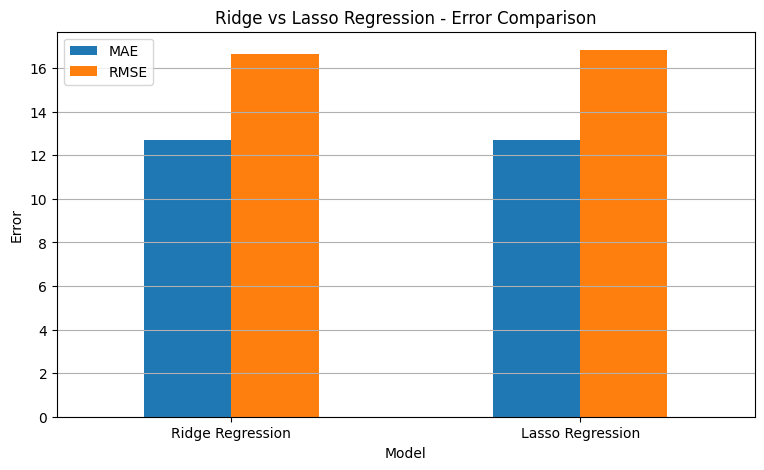

In [ ]:
results_plot = results.set_index("Model")

results_plot[
    ["MAE", "RMSE"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Ridge vs Lasso Regression - Error Comparison")
plt.ylabel("Error")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

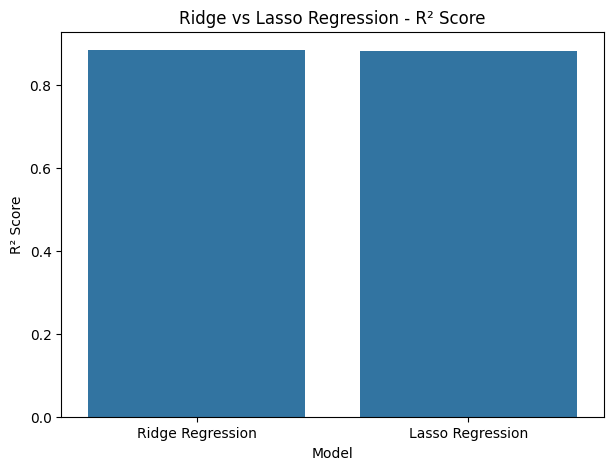

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score"
)

plt.title("Ridge vs Lasso Regression - R² Score")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.show()

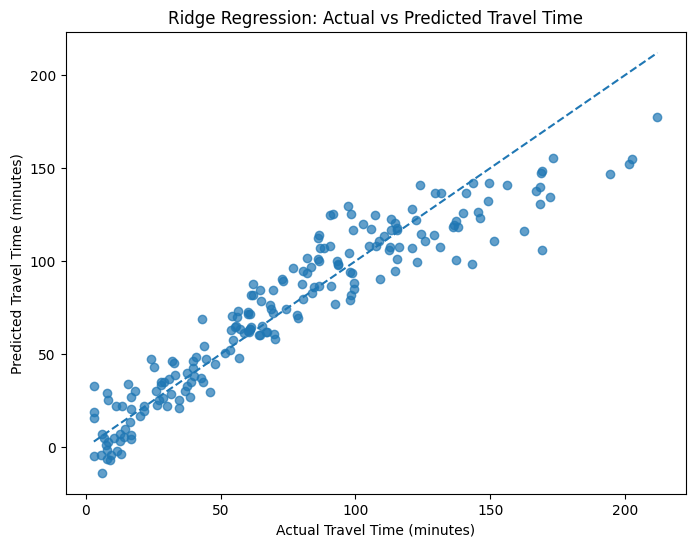

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    ridge_predictions,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Travel Time (minutes)")
plt.ylabel("Predicted Travel Time (minutes)")

plt.title(
    "Ridge Regression: Actual vs Predicted Travel Time"
)

plt.show()

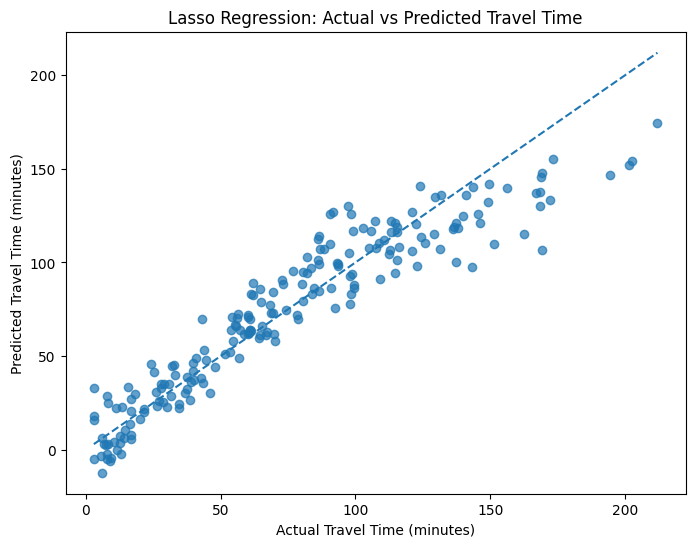

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    lasso_predictions,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Travel Time (minutes)")
plt.ylabel("Predicted Travel Time (minutes)")

plt.title(
    "Lasso Regression: Actual vs Predicted Travel Time"
)

plt.show()

In [ ]:
new_trip = pd.DataFrame({
    "distance_km": [50],
    "traffic_level": ["High"],
    "weather": ["Rainy"],
    "day_of_week": ["Monday"],
    "departure_hour": [18]
})

ridge_prediction = ridge_model.predict(new_trip)[0]
lasso_prediction = lasso_model.predict(new_trip)[0]

print("======================================")
print("NEW TRAVEL TIME PREDICTION")
print("======================================")

print("Distance:", new_trip["distance_km"].iloc[0], "km")
print("Traffic:", new_trip["traffic_level"].iloc[0])
print("Weather:", new_trip["weather"].iloc[0])
print("Day:", new_trip["day_of_week"].iloc[0])
print("Departure Hour:", new_trip["departure_hour"].iloc[0])

print("\nPredicted Travel Time:")

print(
    f"Ridge Regression: "
    f"{ridge_prediction:.2f} minutes"
)

print(
    f"Lasso Regression: "
    f"{lasso_prediction:.2f} minutes"
)

NEW TRAVEL TIME PREDICTION
Distance: 50 km
Traffic: High
Weather: Rainy
Day: Monday
Departure Hour: 18

Predicted Travel Time:
Ridge Regression: 109.08 minutes
Lasso Regression: 108.28 minutes


In [ ]:
print("Enter Travel Details")
print("====================")

distance = float(
    input("Distance (km): ")
)

traffic = input(
    "Traffic Level (Low/Medium/High): "
)

weather = input(
    "Weather (Sunny/Cloudy/Rainy): "
)

day = input(
    "Day of Week: "
)

hour = int(
    input("Departure Hour (0-23): ")
)

user_input = pd.DataFrame({
    "distance_km": [distance],
    "traffic_level": [traffic],
    "weather": [weather],
    "day_of_week": [day],
    "departure_hour": [hour]
})

ridge_result = ridge_model.predict(
    user_input
)[0]

lasso_result = lasso_model.predict(
    user_input
)[0]

print("\n================================")
print("TRAVEL TIME PREDICTION")
print("================================")

print(
    f"Ridge Prediction: "
    f"{ridge_result:.2f} minutes"
)

print(
    f"Lasso Prediction: "
    f"{lasso_result:.2f} minutes"
)

print(
    f"\nRidge ETA approximately: "
    f"{ridge_result / 60:.2f} hours"
)

print(
    f"Lasso ETA approximately: "
    f"{lasso_result / 60:.2f} hours"
)

Enter Travel Details
Distance (km): 20
Traffic Level (Low/Medium/High): Low
Weather (Sunny/Cloudy/Rainy): Sunny
Day of Week: 2
Departure Hour (0-23): 2

TRAVEL TIME PREDICTION
Ridge Prediction: 17.41 minutes
Lasso Prediction: 17.68 minutes

Ridge ETA approximately: 0.29 hours
Lasso ETA approximately: 0.29 hours


In [ ]:
import joblib

joblib.dump(
    ridge_model,
    "ridge_travel_time_model.pkl"
)

joblib.dump(
    lasso_model,
    "lasso_travel_time_model.pkl"
)

print("Models saved successfully!")

Models saved successfully!
